# How to load the dataset and use the plant segmentations

This is the follow-up to `how_to_load.ipynb`. It shows how to:

1. load the private `regularpooria/canopymap_plants` dataset,
2. attach the SAM3 plant tracks in `src/segementation/plant_tracked.jsonl` to the matching dataset rows,
3. decode the masks and draw them on the undistorted frames,
4. use the attached mask areas as a normal tabular column for growth analysis.

> **Access:** you need the Hugging Face token from Discord, and your account must have access to the private dataset.

### What is in `plant_tracked.jsonl`

One JSON object per frame:

```json
{
  "frame": 100,
  "tracks": [
    {
      "id": 1,
      "area": 31491,
      "bbox": [261, 612, 567, 899],
      "rle": {"size": [1920, 1920], "counts": "..."},
      "polygons": [[[408, 612], [407, 613], "..."]]
    }
  ]
}
```

- `frame` is the **row index in `ds["train"]` as loaded by `load_dataset`** (the imagefolder order, not a re-sorted view), not a video frame number. The tracking run used `ds[100:1000]`, so frames 100-999 are annotated.
- `id` is the plant/track id and stays the same across frames.
- `bbox` is `[x1, y1, x2, y2]` (x2 and y2 are exclusive).
- `rle` is COCO compressed RLE; `area` is the number of mask pixels.
- `polygons` are simplified outlines (handy for plotting or editing).
- All coordinates and masks use the **undistorted 1920x1920 frames**, not the raw 2560x1920 images stored in the dataset.

In [1]:
!uv pip install datasets huggingface_hub pillow defisheye matplotlib numpy pandas opencv-python-headless
# OR
# !pip install datasets huggingface_hub pillow defisheye matplotlib numpy pandas opencv-python-headless

Using Python 3.12.16 environment at: /workspaces/CanopyMap/.venv
Resolved 44 packages in 1.14s                                        
Prepared 1 package in 4.28s                                                  opencv-python-headless ------------------------------ 57.90 MiB/58.37 MiB       
Installed 1 package in 165mss==5.0.0.93                     
Bytecode compiled 12 files in 104ms
 + opencv-python-headless==5.0.0.93


In [3]:
import os
from huggingface_hub import login

# Preferred: export HF_TOKEN in your shell. Otherwise paste the token from Discord.
login(token=os.environ.get("HF_TOKEN"))
# login(token=os.environ.get("HF_KEY"))

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Load the dataset

This is the same call as in `how_to_load.ipynb`, but we keep the `train` split as a `Dataset` so we can add columns to it. The dataset is about 1.3 GB, so the first load takes a while; later runs use the local cache.

In [4]:
from datasets import load_dataset

DATASET = "regularpooria/canopymap_plants"
ds = load_dataset(DATASET, split="train")
print(ds)

README.md:   0%|          | 0.00/637 [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  507MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  378MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  405MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3163 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'channel', 'date', 'time', 'suitable', 'ph_boxes_xyxy', 'ph_conf', 'ph_cls', 'ph_polygons'],
    num_rows: 3163
})


### Find and index the tracks file

The full JSONL is about 200 MB, mostly polygon points, so we do not want to load all of it into Python objects. Instead, scan it once and remember the byte offset of each frame. A single frame can then be read on demand.

In [5]:
import json
from pathlib import Path


def find_tracks_file() -> Path:
    """Find plant_tracked.jsonl from the repo root or from src/dataset."""
    candidates = [
        Path("src/segementation/plant_tracked.jsonl"),
        Path("../segementation/plant_tracked.jsonl"),
        Path("../../src/segementation/plant_tracked.jsonl"),
    ]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(
        "Could not find plant_tracked.jsonl. Run this notebook from the repo root "
        "or from src/dataset/."
    )


TRACKS_PATH = find_tracks_file()
print("tracks file:", TRACKS_PATH.resolve())


def index_tracks(path: Path) -> dict[int, int]:
    """Return {frame: byte offset} so one frame can be read without loading the whole file."""
    index = {}
    with open(path, "rb") as f:
        while True:
            offset = f.tell()
            line = f.readline()
            if not line:
                break
            index[json.loads(line)["frame"]] = offset
    return index


tracks_index = index_tracks(TRACKS_PATH)
frames = sorted(tracks_index)
print(f"{len(frames)} annotated frames: {frames[0]}..{frames[-1]}")

tracks file: /workspaces/CanopyMap/src/segementation/plant_tracked.jsonl
900 annotated frames: 100..999


### Attach the segmentations to the dataset

We add compact columns instead of copying the whole JSONL:

| column | type | meaning |
| --- | --- | --- |
| `frame_idx` | `int32` | row index in `ds`; the key used by the JSONL |
| `seg_n_plants` | `int32` | number of tracked plants in this frame |
| `seg_ids` | list of `int32` | plant ids, aligned with the next two columns |
| `seg_bboxes_xyxy` | list of `[x1, y1, x2, y2]` | boxes in undistorted pixels |
| `seg_areas` | list of `int32` | mask area in pixels |
| `seg_rle` | list of `str` | COCO compressed RLE, one string per plant |

RLE is used because it is exact and small: about 18 MB for all 900 frames, versus about 151 MB for the polygon outlines. The polygons stay in the JSONL and are read on demand later in this notebook.

Rows that are not in the JSONL get `seg_n_plants = 0` and empty lists.

In [6]:
from datasets import Sequence, Value

SEG_FEATURES = {
    "frame_idx": Value("int32"),
    "seg_n_plants": Value("int32"),
    "seg_ids": Sequence(Value("int32")),
    "seg_bboxes_xyxy": Sequence(Sequence(Value("float32"), length=4)),
    "seg_areas": Sequence(Value("int32")),
    "seg_rle": Sequence(Value("string")),
}
SEG_COLUMNS = tuple(SEG_FEATURES)


def build_segmentation_columns(dataset, path: Path, index: dict[int, int]):
    """Build one value per dataset row; unannotated rows get empty lists."""
    columns = {name: [] for name in SEG_COLUMNS}
    with open(path, "rb") as f:
        for frame in range(len(dataset)):
            tracks = []
            if frame in index:
                f.seek(index[frame])
                tracks = json.loads(f.readline())["tracks"]

            columns["frame_idx"].append(frame)
            columns["seg_n_plants"].append(len(tracks))
            columns["seg_ids"].append([track["id"] for track in tracks])
            columns["seg_bboxes_xyxy"].append([track["bbox"] for track in tracks])
            columns["seg_areas"].append([track["area"] for track in tracks])
            columns["seg_rle"].append([track["rle"]["counts"] for track in tracks])
    return columns


columns = build_segmentation_columns(ds, TRACKS_PATH, tracks_index)

ds_seg = ds
for name in SEG_COLUMNS:
    ds_seg = ds_seg.add_column(name, columns[name], feature=SEG_FEATURES[name])

del columns  # the dataset now owns the strings
print(ds_seg)

Dataset({
    features: ['image', 'channel', 'date', 'time', 'suitable', 'ph_boxes_xyxy', 'ph_conf', 'ph_cls', 'ph_polygons', 'frame_idx', 'seg_n_plants', 'seg_ids', 'seg_bboxes_xyxy', 'seg_areas', 'seg_rle'],
    num_rows: 3163
})


### Check what was attached

Only the rows listed in `frames` have segmentations. `ds_seg.select(frames)` gives you just those rows without decoding any images.

In [7]:
annotated = ds_seg.select(frames)
print(annotated)
print(f"annotated rows: {len(annotated)} of {len(ds_seg)}")

row = ds_seg[100]
preview = {
    key: (value if key != "seg_rle" else f"<{len(value)} RLE strings>")
    for key, value in row.items()
    if key != "image"
}
print(preview)

Dataset({
    features: ['image', 'channel', 'date', 'time', 'suitable', 'ph_boxes_xyxy', 'ph_conf', 'ph_cls', 'ph_polygons', 'frame_idx', 'seg_n_plants', 'seg_ids', 'seg_bboxes_xyxy', 'seg_areas', 'seg_rle'],
    num_rows: 900
})
annotated rows: 900 of 3163
{'channel': 'channel5', 'date': '2026-05-17', 'time': '15:44:05', 'suitable': True, 'ph_boxes_xyxy': [[446.1000061035156, 1250.9000244140625, 566.0999755859375, 1375.300048828125], [931.0999755859375, 815.9000244140625, 1021.9000244140625, 887.0999755859375], [1182.0, 954.9000244140625, 1283.300048828125, 1042.4000244140625], [721.4000244140625, 1003.0999755859375, 820.7999877929688, 1097.0], [718.0999755859375, 1516.5999755859375, 855.5, 1677.800048828125], [22.799999237060547, 781.2999877929688, 103.0999984741211, 844.7999877929688], [1007.5999755859375, 1192.699951171875, 1109.699951171875, 1311.0999755859375], [731.0, 700.5, 811.9000244140625, 763.5], [521.2000122070312, 853.7999877929688, 612.2999877929688, 929.7999877929688],

### Coordinates: undistort before plotting

The dataset stores raw fisheye images at 2560x1920. The tracker undistorted them to 1920x1920 with `defisheye` before segmenting, so `seg_*` coordinates only line up with the undistorted frame.

The repo already has the correction parameters in `src/utils/distortion.py`; we reuse that function so the notebook cannot drift from the tracker.

In [8]:
import sys
import tempfile

import cv2
import numpy as np

REPO_ROOT = TRACKS_PATH.resolve().parents[2]
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.utils.distortion import de_fish_eye_image

FRAME_SIZE = (1920, 1920)  # (height, width) after de-fishing


def undistort(image):
    """Apply the same fisheye correction that was used for the tracks."""
    with tempfile.TemporaryDirectory() as tmp_dir:
        path = Path(tmp_dir) / "frame.jpg"
        image.convert("RGB").save(path, quality=95)
        bgr = de_fish_eye_image(str(path))
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

### Decode the RLE masks and draw them

COCO RLE stores alternating runs of background and foreground pixels in column-major order. The decoder below is a small, dependency-free version of `pycocotools.mask.decode`; it avoids pinning `pycocotools` and its numpy version constraints.

In [9]:
def decode_rle(counts: str, size=FRAME_SIZE) -> np.ndarray:
    """Decode COCO compressed RLE counts into a boolean (H, W) mask."""
    height, width = size
    lengths = []
    p = 0
    while p < len(counts):
        x = 0
        k = 0
        more = True
        while more:
            c = ord(counts[p]) - 48
            p += 1
            x |= (c & 0x1F) << (5 * k)
            more = c & 0x20
            k += 1
            if not more and (c & 0x10):
                x |= -1 << (5 * k)
        if len(lengths) > 2:
            x += lengths[-2]
        lengths.append(x)

    mask = np.zeros(height * width, dtype=np.uint8)
    i = 0
    value = 0
    for length in lengths:
        if value:
            mask[i : i + length] = 1
        i += length
        value = 1 - value

    if i != height * width:
        raise ValueError(f"RLE covers {i} pixels, expected {height * width}")
    return mask.reshape((height, width), order="F").astype(bool)


def color_for(pid: int):
    """Stable, distinct RGB color per plant id."""
    hsv = np.uint8([[[int(((pid * 0.618) % 1.0) * 179), 220, 255]]])
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)[0, 0]


def show_segmentation(row, ax=None):
    """Undistort one dataset row and draw its tracked plants on top."""
    import matplotlib.patches as patches
    import matplotlib.pyplot as plt

    if ax is None:
        _, ax = plt.subplots(figsize=(9, 9))

    frame = undistort(row["image"])
    if frame.shape[:2] != FRAME_SIZE:
        raise ValueError(
            f"undistorted frame is {frame.shape[:2]}, expected {FRAME_SIZE}; "
            "check the defisheye parameters"
        )

    overlay = np.zeros((*FRAME_SIZE, 4), dtype=np.uint8)
    for pid, (x1, y1, x2, y2), counts in zip(
        row["seg_ids"], row["seg_bboxes_xyxy"], row["seg_rle"]
    ):
        mask = decode_rle(counts, FRAME_SIZE)
        overlay[mask] = (*color_for(pid), 110)
        ax.add_patch(
            patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor="yellow",
                linewidth=1,
                linestyle="--",
            )
        )
        ax.text(
            x1 + 4,
            y1 + 16,
            str(pid),
            color="white",
            fontsize=10,
            weight="bold",
            bbox={"facecolor": "black", "alpha": 0.55, "pad": 1, "edgecolor": "none"},
        )

    ax.imshow(frame)
    ax.imshow(overlay)
    ax.set_title(
        f"frame {row['frame_idx']} | {row['channel']} | "
        f"{row['date']} {row['time']} | {row['seg_n_plants']} plants",
        fontsize=10,
    )
    ax.axis("off")
    return ax

### Show one frame

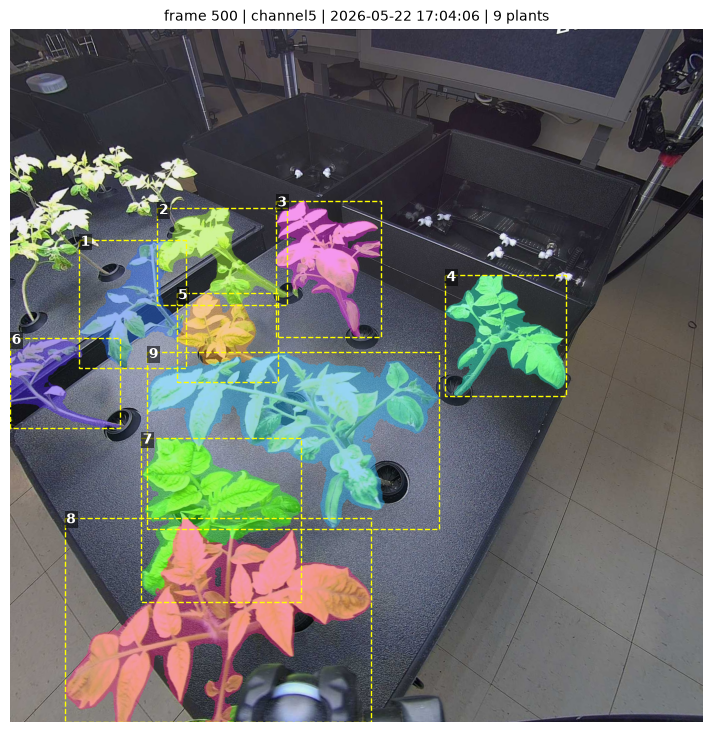

In [11]:
import matplotlib.pyplot as plt

show_segmentation(ds_seg[500])
plt.show()

### Compare frames over time

The track ids follow the same plant across the whole run, so the colors are consistent between frames.

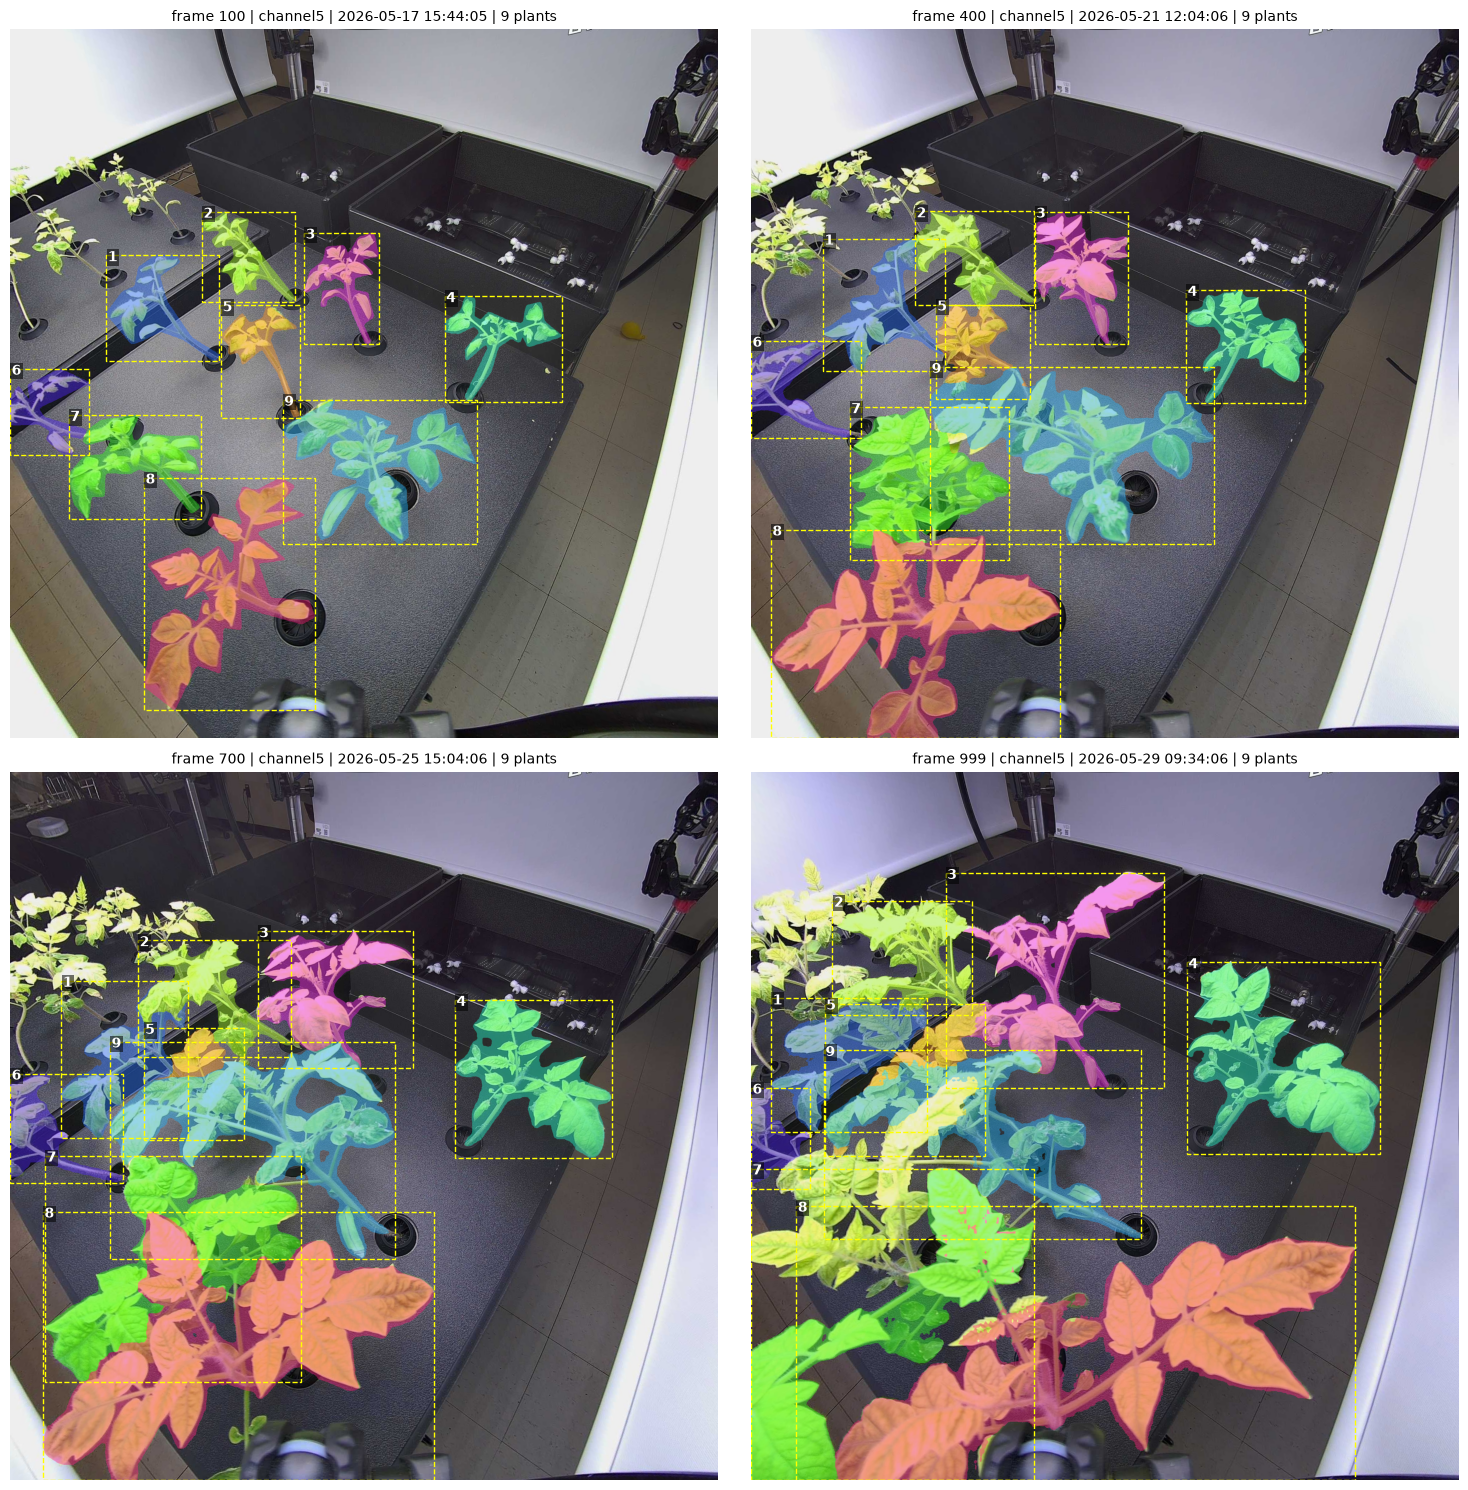

In [12]:
frames_to_show = [100, 400, 700, 999]

fig, axes = plt.subplots(2, 2, figsize=(15, 15))
for ax, frame in zip(axes.flat, frames_to_show):
    show_segmentation(ds_seg[frame], ax=ax)
plt.tight_layout()
plt.show()

### Polygons on demand

The attached columns use RLE because it is compact. The JSONL also has simplified polygons, which are convenient for plotting, editing, or exporting to COCO. Read only the frame you need:

In [14]:
def load_frame_tracks(frame, path: Path = TRACKS_PATH, index: dict[int, int] = tracks_index):
    """Read one frame's full track records, including polygons and RLE."""
    if frame not in index:
        return []
    with open(path, "rb") as f:
        f.seek(index[frame])
        return json.loads(f.readline())["tracks"]


tracks_100 = load_frame_tracks(100)
print(f"{len(tracks_100)} tracks on frame 100")
print(
    {
        key: (value if key not in {"rle", "polygons"} else f"<{key}>")
        for key, value in tracks_100[0].items()
    }
)

9 tracks on frame 100
{'id': 1, 'area': 31491, 'bbox': [261, 612, 567, 899], 'rle': '<rle>', 'polygons': '<polygons>'}


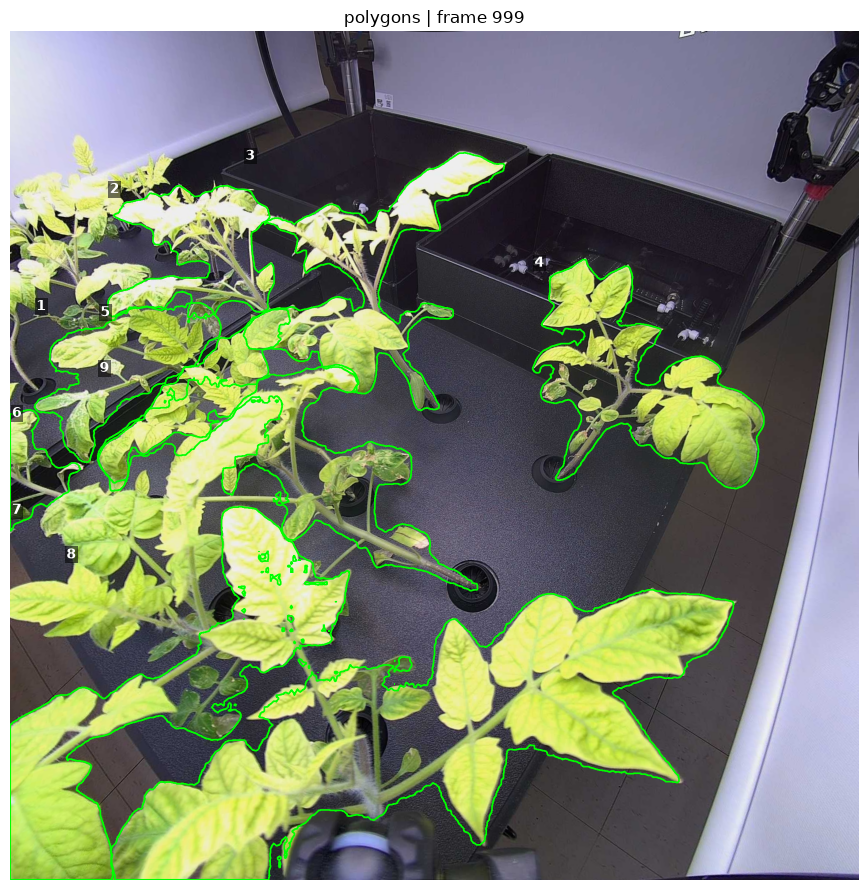

In [15]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt

row = ds_seg[999]
frame = undistort(row["image"])

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(frame)
for track in load_frame_tracks(row["frame_idx"]):
    for ring in track["polygons"]:
        ax.add_patch(patches.Polygon(np.asarray(ring), fill=False, edgecolor="lime", linewidth=1.2))
    x1, y1, _, _ = track["bbox"]
    ax.text(
        x1 + 4,
        y1 + 16,
        str(track["id"]),
        color="white",
        fontsize=10,
        weight="bold",
        bbox={"facecolor": "black", "alpha": 0.55, "pad": 1, "edgecolor": "none"},
    )

ax.set_title(f"polygons | frame {row['frame_idx']}")
ax.axis("off")
plt.tight_layout()
plt.show()

### Save or publish the attached dataset

These cells are optional and deliberately commented out. Option 2 changes the shared private dataset, so coordinate with the team before running it.

In [ ]:
# Option 1: keep the attached dataset on this machine (fast, no Hugging Face upload).
# ds_seg.save_to_disk("canopymap_plants_with_segmentation")

# Option 2: add the new columns to the same private dataset.
# This replaces the dataset schema and re-uploads the images (about 1.3 GB).
# ds_seg.push_to_hub(DATASET, private=True)

# Option 3: publish only the lightweight segmentation table (no images) as a companion dataset.
# ds_seg.remove_columns("image").push_to_hub(
#     "regularpooria/canopymap_plants_segmentations", private=True
# )

In [19]:
ds_seg.remove_columns(["image"]).push_to_hub(
    "regularpooria/canopymap_plants",
    config_name="segmentations",
    split="train",
    private=True,
    commit_message="Adding segmentation information for the plants",
    create_pr=True,
)

Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

CommitInfo(commit_url='https://huggingface.co/datasets/regularpooria/canopymap_plants/commit/306b93f8bec2d668af132b0b01898c79bcbdfa43', commit_message='Adding segmentation information for the plants', commit_description='', oid='306b93f8bec2d668af132b0b01898c79bcbdfa43', pr_url='https://huggingface.co/datasets/regularpooria/canopymap_plants/discussions/2', repo_url=RepoUrl('https://huggingface.co/datasets/regularpooria/canopymap_plants', endpoint='https://huggingface.co', repo_type='dataset', repo_id='regularpooria/canopymap_plants'), pr_revision='refs/pr/2', pr_num=2)

### Troubleshooting and notes

- **Access denied / 401:** check that you are logged in and that your account has access to the private dataset.
- **`FileNotFoundError` for the JSONL:** start Jupyter from the repo root or from `src/dataset/`, or edit `find_tracks_file()`.
- **Masks look offset:** you are probably drawing on the raw image. Use `undistort(row["image"])`; `seg_*` uses the 1920x1920 undistorted frame.
- **Frame mapping:** `frame` is the row index used when the tracker ran (`ds[100:1000]`). If the dataset is re-uploaded or reordered, rebuild the mapping. The robust long-term fix is to write `channel`, `date`, and `time` into the JSONL as well.
- **Other columns:** the existing `ph_*` columns are plant-holder detections, not the tracked plant segmentations. The new columns are all prefixed with `seg_`.
- **RLE size:** all masks are 1920x1920. If you change the `defisheye` parameters, resize or re-encode the masks before using them.